# Classificação de gatos, cachorros e pandas com CNN — TensorFlow/Keras

**Continuação dos experimentos KNN, SVM e MLP.
 → construir CNN → compilar → treinar → avaliar → prever**, agora com três classes.

**Mudança fundamental:** a entrada é a **imagem RGB inteira** redimensionada para 128 × 128 pixels; **não há HOG, ANOVA, LBP ou seleção manual de características**. Os filtros convolucionais são aprendidos durante o treinamento.

**Comparação justa:** reutilizamos as pastas já separadas em `treino`, `validacao` e `teste`, sem refazer o particionamento. O notebook treina uma CNN pequena **do zero**, sem *transfer learning*; o desempenho não é garantido e poderá ser comparado com o SVM e a MLP.

## 1. O problema continua com **três categorias** (`cats`, `dogs`, `panda`).

- **Entrada:** `(128, 128, 3)` — altura, largura e canais RGB.
- **Saída:** três neurônios `softmax` — probabilidades das três classes.
- **Perda:** `sparse_categorical_crossentropy`, pois os rótulos serão números inteiros `0`, `1` e `2`.
- **Treinamento:** `model.fit(...)` (API atual), com `EarlyStopping` e `ModelCheckpoint`.

A CNN aprende filtros que respondem a padrões locais da imagem. **CNNs podem ser mais adequadas a imagens naturais do que HOG + classificadores clássicos, mas não garantem melhor acurácia com apenas 1.050 imagens de treinamento.**

## 2. Importação das bibliotecas e reprodutibilidade

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, precision_recall_fscore_support)

# Para que os experimentos possam ser reproduzidos (até onde o hardware permitir).
SEMENTE = 42
keras.utils.set_random_seed(SEMENTE)
print('TensorFlow:', tf.__version__)
print('GPUs disponíveis:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPUs disponíveis: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Conectar o Google Drive e localizar o dataset

O diretório abaixo deve conter `treino`, `validacao` e `teste`; dentro de cada um devem existir as pastas `cats`, `dogs` e `panda`. Não fazemos outra divisão dos dados.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

PASTA_DADOS = Path('/content/drive/MyDrive/knnsvmtest_dividido')
CLASSES = ['cats', 'dogs', 'panda']
PARTES = ['treino', 'validacao', 'teste']

for parte in PARTES:
    for classe in CLASSES:
        pasta = PASTA_DADOS / parte / classe
        if not pasta.is_dir():
            raise FileNotFoundError(f'Pasta não encontrada: {pasta}')
print('Estrutura de pastas encontrada:', PASTA_DADOS)

Mounted at /content/drive
Estrutura de pastas encontrada: /content/drive/MyDrive/knnsvmtest_dividido


## 4. Conferir a quantidade de imagens por classe e por conjunto

In [ ]:
EXTENSOES = {'.jpg', '.jpeg', '.png', '.bmp', '.gif'}
linhas = []
for parte in PARTES:
    for classe in CLASSES:
        arquivos = [p for p in (PASTA_DADOS / parte / classe).iterdir()
                    if p.is_file() and p.suffix.lower() in EXTENSOES]
        linhas.append({'conjunto': parte, 'classe': classe, 'quantidade': len(arquivos)})
contagem = pd.DataFrame(linhas)
display(contagem.pivot(index='conjunto', columns='classe', values='quantidade').reindex(PARTES))
print('Total de imagens:', contagem['quantidade'].sum())
assert (contagem['quantidade'] > 0).all(), 'Há alguma classe vazia!'
# Esperado no experimento anterior: 350/75/75 por classe, mas não forçamos
# esses valores para permitir reutilizar a estrutura caso haja ajustes.

classe,cats,dogs,panda
conjunto,,,
treino,350,350,350
validacao,75,75,75
teste,75,75,75


Total de imagens: 1500


## 5. Ler imagens RGB diretamente do disco

`image_dataset_from_directory` lê os arquivos e atribui rótulos conforme o nome das pastas. Usamos **`class_names=CLASSES`** para fixar a ordem dos rótulos nos três conjuntos. Cada imagem é redimensionada para **128 × 128**, preservando os **três canais de cor**. A normalização `[0, 255] → [0, 1]` será realizada **dentro da CNN**.

In [ ]:
TAMANHO_IMAGEM = (128, 128)
BATCH_SIZE = 32

# Importante: não embaralhar validação e teste, para manter previsões e
# rótulos na mesma ordem ao calcular as métricas e a matriz de confusão.
def carregar_conjunto(nome, embaralhar):
    return keras.utils.image_dataset_from_directory(
        PASTA_DADOS / nome,
        labels='inferred',
        label_mode='int',
        class_names=CLASSES,
        image_size=TAMANHO_IMAGEM,
        batch_size=BATCH_SIZE,
        shuffle=embaralhar,
        seed=SEMENTE
    )

treino_ds = carregar_conjunto('treino', True)
validacao_ds = carregar_conjunto('validacao', False)
teste_ds = carregar_conjunto('teste', False)

# Acelera a preparação dos lotes sem carregar obrigatoriamente tudo na RAM.
AUTOTUNE = tf.data.AUTOTUNE
treino_ds = treino_ds.prefetch(AUTOTUNE)
validacao_ds = validacao_ds.prefetch(AUTOTUNE)
teste_ds = teste_ds.prefetch(AUTOTUNE)

Found 1050 files belonging to 3 classes.
Found 225 files belonging to 3 classes.
Found 225 files belonging to 3 classes.


## 6. Visualizar exemplos das imagens de entrada

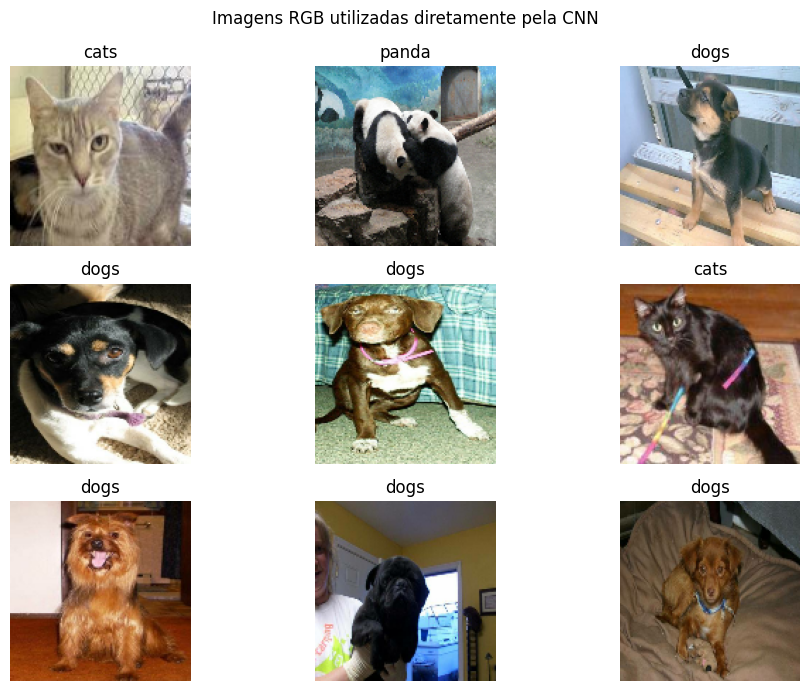

In [ ]:
plt.figure(figsize=(10, 7))
for imagens, rotulos in treino_ds.take(1):
    for i in range(min(9, len(imagens))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(imagens[i].numpy().astype('uint8'))
        plt.title(CLASSES[int(rotulos[i])])
        plt.axis('off')
plt.suptitle('Imagens RGB utilizadas diretamente pela CNN')
plt.tight_layout()
plt.show()

## 7. Arquitetura da rede convolucional

Inspirada na sequência de camadas do notebook de raio-X, mas ajustada para três classes e imagens coloridas:

```text
Imagem RGB (128 × 128 × 3)
        ↓
Rescaling(1/255) — normalização
        ↓
Conv2D (32 filtros, 3×3) + ReLU → MaxPooling2D
        ↓
Conv2D (64 filtros, 3×3) + ReLU → MaxPooling2D
        ↓
Conv2D (128 filtros, 3×3) + ReLU → MaxPooling2D
        ↓
Flatten → Dense (128, ReLU) → Dropout (0,4)
        ↓
Dense (3, softmax) → gato / cachorro / panda
```

**Convolução:** aprende filtros locais. **Pooling:** reduz dimensões espaciais. **Flatten:** converte mapas de características em um vetor. **Dense:** combina as informações para classificar. **Dropout:** ajuda a reduzir sobreajuste durante o treinamento.

Esta primeira CNN **não usa aumento de dados**: isso facilita compreender a arquitetura e mantém uma referência inicial. Aumento de dados pode ser experimentado posteriormente, somente no treino.

In [ ]:
def construir_cnn():
    # A entrada é a imagem inteira, e não um vetor HOG.
    modelo = keras.Sequential([
        layers.Input(shape=(128, 128, 3)),
        layers.Rescaling(1./255),

        # Primeiro bloco: aprende padrões simples, como bordas e texturas.
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        # Segundo bloco: combina padrões visuais em estruturas maiores.
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        # Terceiro bloco: aprende representações visuais mais complexas.
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        # Transformação para as camadas densas de classificação.
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.4),

        # Três probabilidades (somam aproximadamente 1).
        layers.Dense(3, activation='softmax')
    ], name='CNN_Gatos_Cachorros_Pandas')
    return modelo

modelo = construir_cnn()
modelo.summary()

Model: "CNN_Gatos_Cachorros_Pandas"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,067 (16.36 MB)

 Trainable params: 4,288,067 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

## 8. Compilar o modelo

A função de perda `sparse_categorical_crossentropy` é adequada para **três classes mutuamente exclusivas**, codificadas como números inteiros. A saída `softmax` produz três probabilidades. O otimizador Adam atualiza os pesos dos filtros e das camadas densas.

In [ ]:
modelo.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

## 9. Treinamento com EarlyStopping e ModelCheckpoint

- `EarlyStopping`: interrompe o treinamento se a perda de validação não melhorar por várias épocas e restaura os melhores pesos.
- `ModelCheckpoint`: salva o melhor modelo observado na validação.
- **Nunca usamos o conjunto de teste para ajustar o modelo.**

A rede será treinada do zero. O número máximo de épocas não significa que todas serão executadas.

In [ ]:
ARQUIVO_MODELO = '/content/cnn_animais_melhor.keras'

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=ARQUIVO_MODELO,
        monitor='val_loss',
        mode='min',
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        mode='min',
        patience=7,
        restore_best_weights=True,
        verbose=1
    )
]

historico = modelo.fit(
    treino_ds,
    validation_data=validacao_ds,
    epochs=40,
    callbacks=callbacks
)

Epoch 1/40
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.4232 - loss: 1.1187
Epoch 1: val_loss improved from None to 0.81278, saving model to /content/cnn_animais_melhor.keras

Epoch 1: finished saving model to /content/cnn_animais_melhor.keras
33/33 ━━━━━━━━━━━━━━━━━━━━ 392s 12s/step - accuracy: 0.4981 - loss: 0.9816 - val_accuracy: 0.5778 - val_loss: 0.8128
Epoch 2/40
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.5538 - loss: 0.8644
Epoch 2: val_loss improved from 0.81278 to 0.71136, saving model to /content/cnn_animais_melhor.keras

Epoch 2: finished saving model to /content/cnn_animais_melhor.keras
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 90ms/step - accuracy: 0.5857 - loss: 0.8182 - val_accuracy: 0.6711 - val_loss: 0.7114
Epoch 3/40
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.6035 - loss: 0.7764
Epoch 3: val_loss improved from 0.71136 to 0.65113, saving model to /content/cnn_animais_melhor.keras

Epoch 3: finished saving model to /content/cnn_animais_melhor.keras
33/3

## 10. Curvas de aprendizado: acurácia e perda

Se a acurácia de treino continuar crescendo enquanto a validação piora, pode haver **sobreajuste (*overfitting*)**. As curvas ajudam a discutir o comportamento da rede durante o treinamento.

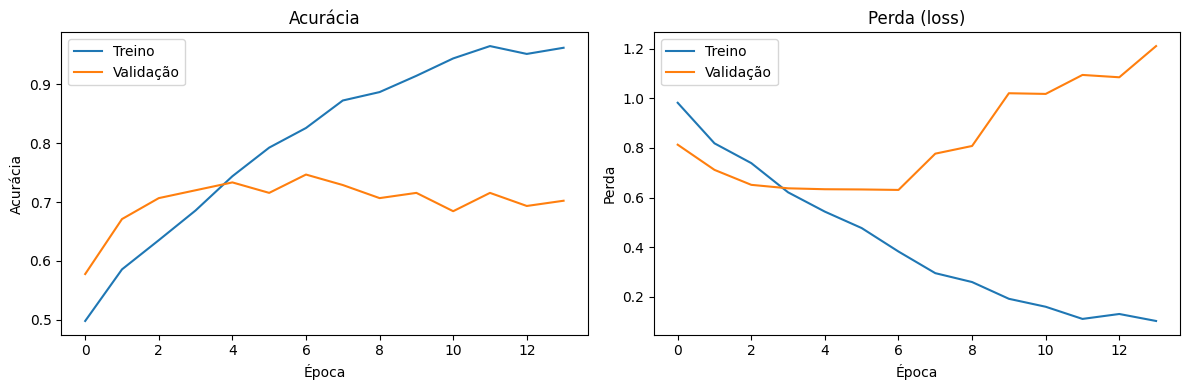

In [ ]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
eixos[0].plot(historico.history['accuracy'], label='Treino')
eixos[0].plot(historico.history['val_accuracy'], label='Validação')
eixos[0].set(title='Acurácia', xlabel='Época', ylabel='Acurácia')
eixos[0].legend()

eixos[1].plot(historico.history['loss'], label='Treino')
eixos[1].plot(historico.history['val_loss'], label='Validação')
eixos[1].set(title='Perda (loss)', xlabel='Época', ylabel='Perda')
eixos[1].legend()
plt.tight_layout()
plt.show()

## 11. Avaliar o modelo escolhido no conjunto de validação

Recarregamos o melhor modelo salvo, selecionado pela **menor perda de validação**. Esta avaliação serve para observar seu desempenho antes de consultar o conjunto de teste.

In [ ]:
modelo = keras.models.load_model(ARQUIVO_MODELO)
perda_val, acuracia_val = modelo.evaluate(validacao_ds, verbose=0)
print(f'Validação — perda: {perda_val:.4f} | acurácia: {acuracia_val:.4f}')

Validação — perda: 0.6306 | acurácia: 0.7467


## 12. Avaliação final no conjunto de teste

Calculamos acurácia, precisão, recall e F1 macro com imagens que **não participaram do treinamento nem da seleção do modelo**. A ordem dos rótulos coincide com a das previsões porque `teste_ds` foi carregado com `shuffle=False`.

In [ ]:
# Recupera todos os rótulos verdadeiros do conjunto de teste.
y_real = np.concatenate([rotulos.numpy() for _, rotulos in teste_ds])

# Prediz probabilidades para cada uma das três classes.
probabilidades = modelo.predict(teste_ds, verbose=0)
y_previsto = np.argmax(probabilidades, axis=1)

acuracia = accuracy_score(y_real, y_previsto)
precisao, recall, f1, _ = precision_recall_fscore_support(
    y_real, y_previsto, average='macro', zero_division=0
)

print('AVALIAÇÃO FINAL — CNN com imagens RGB')
print(f'Acurácia:       {acuracia:.4f}')
print(f'Precisão macro: {precisao:.4f}')
print(f'Recall macro:   {recall:.4f}')
print(f'F1 macro:      {f1:.4f}')
print()
print('Relatório por classe:')
print(classification_report(y_real, y_previsto, labels=[0, 1, 2],
                            target_names=CLASSES, zero_division=0))

AVALIAÇÃO FINAL — CNN com imagens RGB
Acurácia:       0.7289
Precisão macro: 0.7338
Recall macro:   0.7289
F1 macro:      0.7227

Relatório por classe:
              precision    recall  f1-score   support

        cats       0.61      0.79      0.69        75
        dogs       0.67      0.48      0.56        75
       panda       0.92      0.92      0.92        75

    accuracy                           0.73       225
   macro avg       0.73      0.73      0.72       225
weighted avg       0.73      0.73      0.72       225



## 13. Matriz de confusão

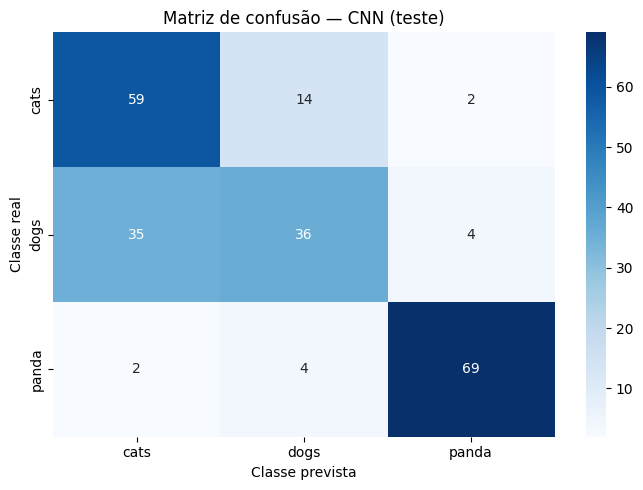

In [ ]:
matriz = confusion_matrix(y_real, y_previsto, labels=[0, 1, 2])
plt.figure(figsize=(7, 5))
sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel('Classe prevista')
plt.ylabel('Classe real')
plt.title('Matriz de confusão — CNN (teste)')
plt.tight_layout()
plt.show()

## 14. Visualizar previsões em imagens do teste

Exibimos algumas imagens com a classe real e a previsão. **As previsões são feitas sem informar ao modelo a classe correta**: os rótulos reais servem apenas para conferir os resultados.

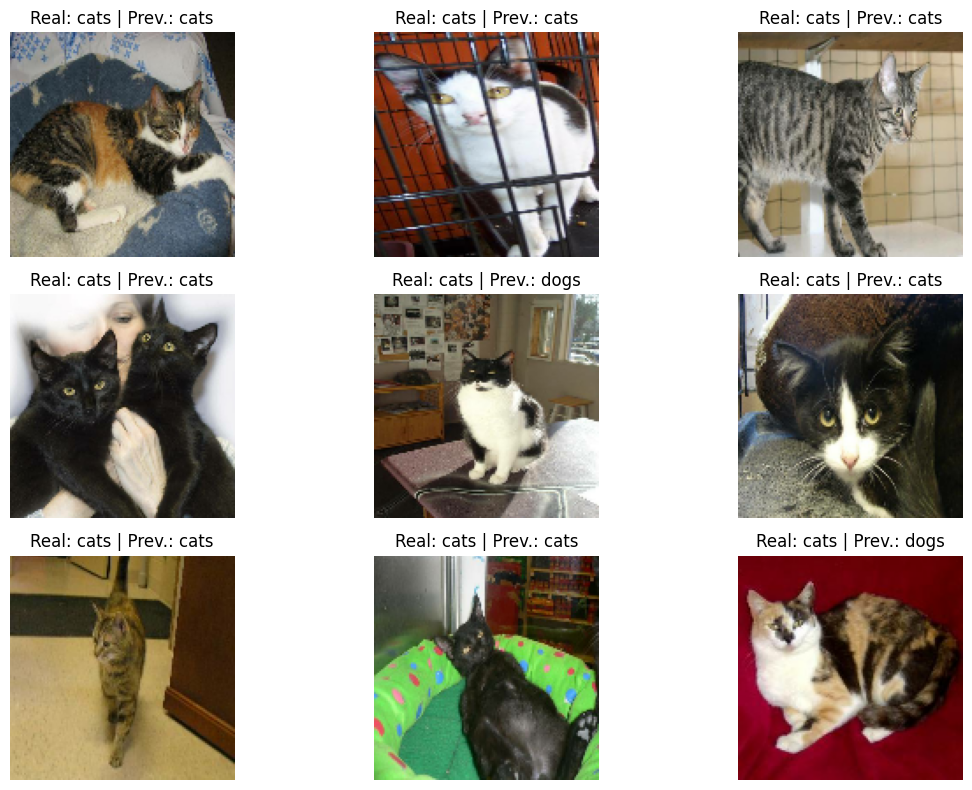

In [ ]:
plt.figure(figsize=(12, 8))
for imagens, rotulos in teste_ds.take(1):
    prob_lote = modelo.predict(imagens, verbose=0)
    pred_lote = np.argmax(prob_lote, axis=1)
    for i in range(min(9, len(imagens))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(imagens[i].numpy().astype('uint8'))
        real = CLASSES[int(rotulos[i])]
        previsto = CLASSES[int(pred_lote[i])]
        plt.title(f'Real: {real} | Prev.: {previsto}')
        plt.axis('off')
plt.tight_layout()
plt.show()

## 15. Classificar uma imagem individual (inclusive fora do dataset)

O usuário escolhe o caminho da imagem. A CNN recebe a **imagem RGB inteira** (redimensionada para 128 × 128), e retorna as probabilidades das três classes. **Não é necessário extrair HOG ou aplicar ANOVA.**

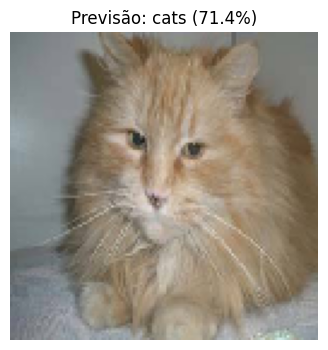

cats: 71.38%
dogs: 28.28%
panda: 0.34%


In [ ]:
# Troque pelo caminho real da imagem que deseja classificar.
caminho_imagem = '/content/drive/MyDrive/test_animals/cats/cats_00019.jpg'

if not Path(caminho_imagem).is_file():
    print('Imagem não encontrada. Atualize caminho_imagem para executar esta célula.')
else:
    imagem = keras.utils.load_img(caminho_imagem, target_size=TAMANHO_IMAGEM,
                                  color_mode='rgb')
    matriz_rgb = keras.utils.img_to_array(imagem)  # Valores 0 a 255.
    lote = np.expand_dims(matriz_rgb, axis=0)       # Forma (1, 128, 128, 3).

    # A normalização ocorre dentro do modelo, na camada Rescaling.
    probs = modelo.predict(lote, verbose=0)[0]
    indice = int(np.argmax(probs))

    plt.figure(figsize=(5, 4))
    plt.imshow(imagem)
    plt.title(f'Previsão: {CLASSES[indice]} ({probs[indice]:.1%})')
    plt.axis('off')
    plt.show()

    for nome, prob in zip(CLASSES, probs):
        print(f'{nome}: {prob:.2%}')

## 16. Salvar o modelo treinado no Google Drive

O arquivo `.keras` contém a arquitetura e os pesos aprendidos. Depois de salvar, é possível reutilizá-lo sem treinar novamente. O modelo salvo recebe diretamente imagens RGB de 128 × 128, com valores de pixel entre 0 e 255.

In [ ]:
CAMINHO_SALVO = PASTA_DADOS.parent / 'cnn_gatos_cachorros_pandas.keras'
modelo.save(CAMINHO_SALVO)
print('Modelo salvo em:', CAMINHO_SALVO)